In [14]:
#Comenzaremos subiendo nuestra base de datos y la convertiremos en un DataFrame de pandas.
import pandas as pd
df1 = pd.read_csv('C:\\Users\\yetla\\Downloads\\archivo_limpio.csv')
df2 = pd.read_csv('C:\\Users\\yetla\\Downloads\\datos_vivaaerobus_actualizado.csv')
# Reemplaza 'ruta_base1.csv' y 'ruta_base2.csv' por la ubicación de tus archivos
print(df.head())

  fecha_extraccion hora_extraccion                  origen  \
0       10/10/2025        22:30:18  Ciudad de México (MEX)   
1       10/10/2025        22:30:43  Ciudad de México (MEX)   
2       10/10/2025        22:31:05  Ciudad de México (MEX)   
3       11/10/2025        20:45:44  Ciudad de México (MEX)   
4       11/10/2025        20:46:09  Ciudad de México (MEX)   

                  destino  dia_salida hora_salida  precio   aerolinea  \
0       Guadalajara (GDL)  20/12/2025       06:20  2196.0  Aeroméxico   
1          Veracruz (VER)  20/12/2025       06:35  2647.0  Aeroméxico   
2         Chihuahua (CUU)  20/12/2025       06:10  4792.0  Aeroméxico   
3  Tuxtla Gutiérrez (TGZ)  20/12/2025       09:35  7656.0  Aeroméxico   
4       Guadalajara (GDL)  20/12/2025       06:20  2196.0  Aeroméxico   

   kilometros disponibilidad  numero_de_vuelo  Dias_anticipacion  \
0         460     Disponible                1                 71   
1         320     Disponible                1       

In [15]:
df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_")
    .str.normalize('NFKD')
    .str.encode('ascii', errors='ignore')
    .str.decode('utf-8')
)


In [17]:
print(df1.columns.tolist())


['fecha_extraccion', 'hora_extraccion', 'origen', 'destino', 'dia_salida', 'hora_salida', 'precio', 'aerolinea', 'kilometros', 'disponibilidad', 'numero de vuelo', 'Días_anticipación ', 'Mes/Dia del vuelo', 'Ruta', 'Hora_vuelo', 'Aerolinea']


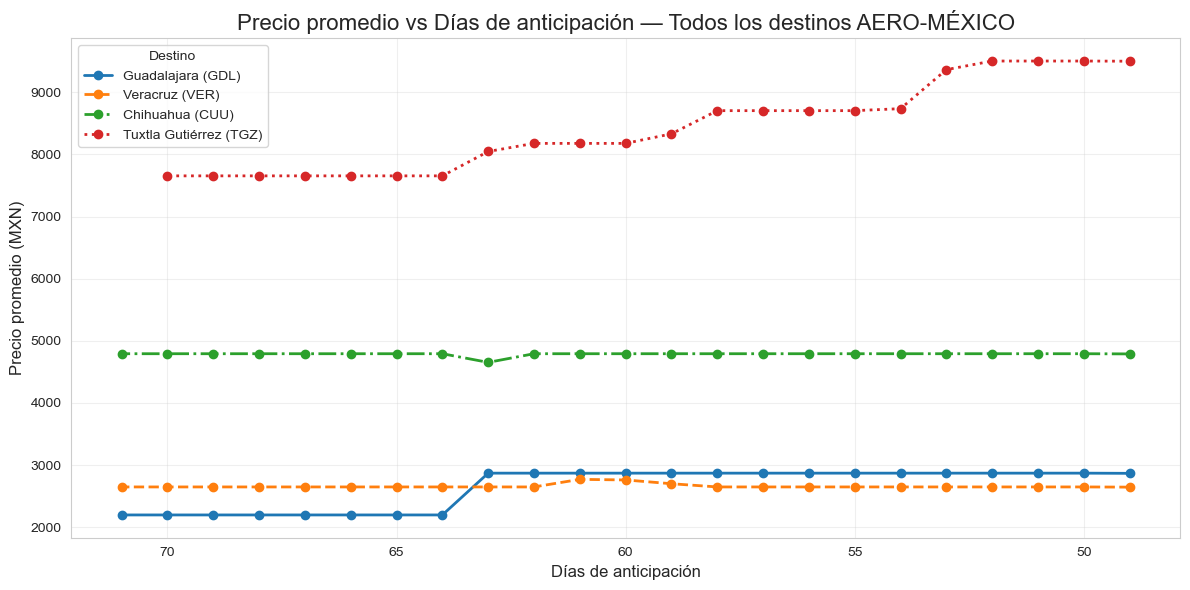

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética
sns.set_style("whitegrid")  # estilo limpio con cuadrícula
plt.figure(figsize=(12,6))

# Asegurar que precio sea numérico
df["precio"] = df["precio"].replace('[\$,]', '', regex=True).astype(float)

# Colores y estilos para cada destino
colors = sns.color_palette("tab10", n_colors=len(df["destino"].unique()))
linestyles = ['-', '--', '-.', ':']

# Graficar todos los destinos juntos
for i, dest in enumerate(df["destino"].unique()):
    df_dest = df[df["destino"] == dest]
    g = df_dest.groupby("Dias_anticipacion")["precio"].mean()
    
    plt.plot(
        g.index, g.values, 
        marker='o', 
        color=colors[i % len(colors)], 
        linestyle=linestyles[i % len(linestyles)],
        linewidth=2,
        markersize=6,
        label=f"{dest}"
    )

# Mejoras de aspecto
plt.title("Precio promedio vs Días de anticipación — Todos los destinos AERO-MÉXICO", fontsize=16)
plt.xlabel("Días de anticipación", fontsize=12)
plt.ylabel("Precio promedio (MXN)", fontsize=12)
plt.gca().invert_xaxis()  # invertir eje X
plt.grid(alpha=0.3)
plt.legend(title="Destino")
plt.tight_layout()

plt.show()


In [25]:
import sys
!{sys.executable} -m pip install pwlf


  Using cached pwlf-2.5.2-py3-none-any.whl.metadata (6.4 kB)
Using cached pwlf-2.5.2-py3-none-any.whl (17 kB)


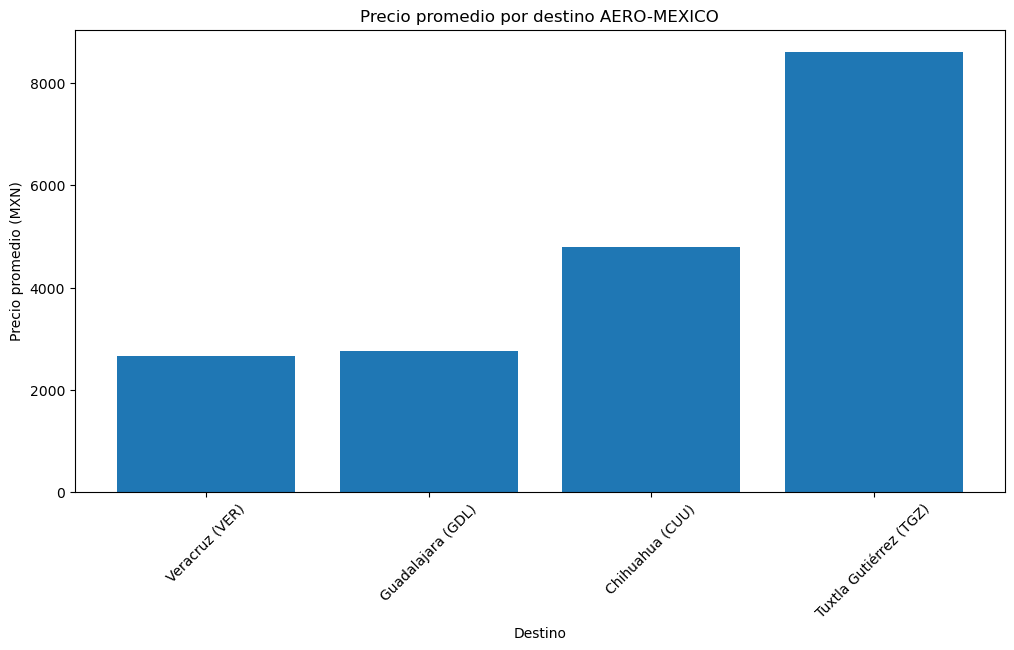

In [14]:
g2 = df.groupby("destino")["precio"].mean().sort_values()

plt.figure(figsize=(12,6))
plt.bar(g2.index, g2.values)
plt.title("Precio promedio por destino AERO-MEXICO")
plt.xlabel("Destino")
plt.ylabel("Precio promedio (MXN)")
plt.xticks(rotation=45)
plt.show()


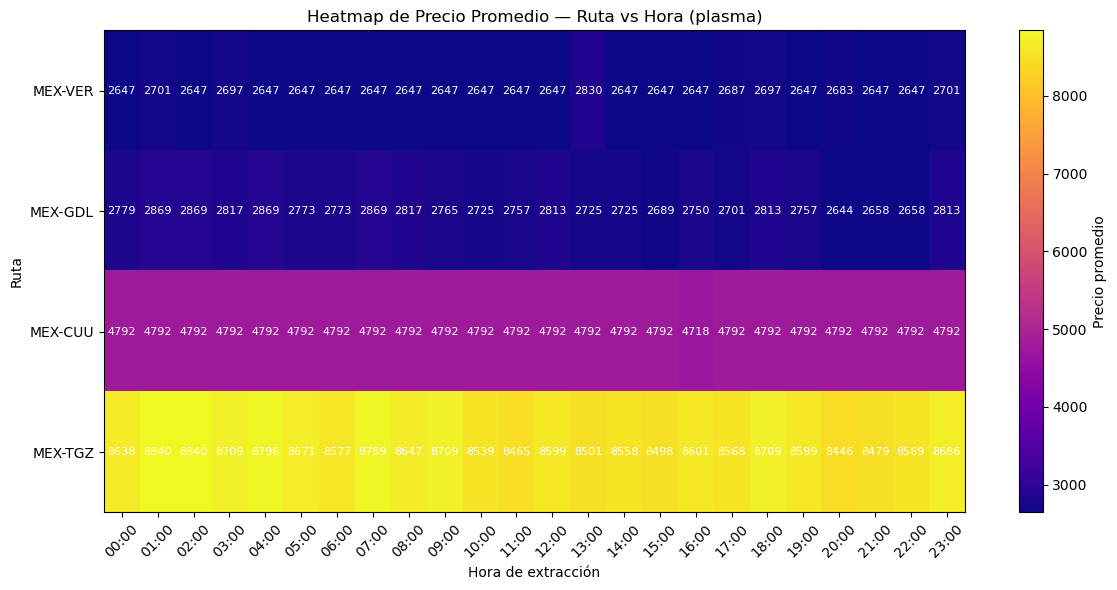

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# === Limpiar precio ===
df["precio"] = (
    df["precio"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "")
    .astype(float)
)

# === Convertir hora ===
df["hora_extraccion"] = pd.to_datetime(df["hora_extraccion"], errors="coerce")

# Redondear a la hora
df["hora_redondeada"] = df["hora_extraccion"].dt.floor("H").dt.strftime("%H:%M")

# === Clasificación automática de rutas por precio promedio ===
promedios_ruta = df.groupby("Ruta")["precio"].mean().sort_values()
rutas_ordenadas = promedios_ruta.index.tolist()

# === Crear pivot ordenado ===
pivot = df.pivot_table(
    index="Ruta",
    columns="hora_redondeada",
    values="precio",
    aggfunc="mean"
).reindex(rutas_ordenadas)

# === Seleccionar colormap (elige uno: 'plasma', 'viridis', 'magma') ===
cmap_elegido = "plasma"     # <-- cambia aquí

# === Crear heatmap ===
plt.figure(figsize=(12, 6))
plt.imshow(pivot, aspect="auto", cmap=cmap_elegido)
plt.colorbar(label="Precio promedio")

# Etiquetas
plt.xticks(
    ticks=np.arange(len(pivot.columns)),
    labels=pivot.columns,
    rotation=45
)
plt.yticks(
    ticks=np.arange(len(pivot.index)),
    labels=pivot.index
)

plt.title(f"Heatmap de Precio Promedio — Ruta vs Hora ({cmap_elegido})")
plt.xlabel("Hora de extracción")
plt.ylabel("Ruta")

# === Anotaciones ===
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        valor = pivot.iloc[i, j]
        if not pd.isna(valor):
            plt.text(
                j, i,
                f"{valor:.0f}",
                ha="center",
                va="center",
                color="white" if cmap_elegido in ["magma", "plasma"] else "black",
                fontsize=8
            )

plt.tight_layout()
plt.show()
